In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [19]:
df = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/AutoEncoder/Energy Consumption/energy consumption.csv")

In [20]:
df.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,01-01-2024 00:00,0.457786,0.469524,0.396368,0.445441,0.692057,0
1,01-01-2024 00:30,0.351956,0.465545,0.451184,0.458729,0.539874,0
2,01-01-2024 01:00,0.482948,0.285415,0.408289,0.470360,0.614724,0
3,01-01-2024 01:30,0.628838,0.482095,0.512308,0.576241,0.757044,0
4,01-01-2024 02:00,0.335974,0.624741,0.672021,0.373004,0.673981,0


In [21]:
X = df.iloc[:,1:-1].values
y = df.iloc[:,-1].values
X

array([[0.45778569, 0.46952446, 0.39636836, 0.4454406 , 0.69205721],
       [0.35195595, 0.46554478, 0.45118441, 0.45872929, 0.53987374],
       [0.48294809, 0.28541499, 0.40828897, 0.47036041, 0.61472396],
       ...,
       [0.89381837, 0.43173895, 0.6889256 , 0.50803789, 0.68109888],
       [0.5096727 , 0.59292656, 0.3661509 , 0.66821811, 0.710599  ],
       [0.23365573, 0.61287204, 0.47348062, 0.26830621, 0.55528629]])

In [22]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
X

array([[0.45778569, 0.46952446, 0.39636836, 0.4454406 , 0.69205721],
       [0.35195595, 0.46554478, 0.45118441, 0.45872929, 0.53987374],
       [0.48294809, 0.28541499, 0.40828897, 0.47036041, 0.61472396],
       ...,
       [0.89381837, 0.43173895, 0.6889256 , 0.50803789, 0.68109888],
       [0.5096727 , 0.59292656, 0.3661509 , 0.66821811, 0.710599  ],
       [0.23365573, 0.61287204, 0.47348062, 0.26830621, 0.55528629]])

In [23]:
X_seq = []
y_seq = []

for i in range(len(X)-10+1):
    X_seq.append(X[i:i+10])
    y_seq.append(y[i+9])

X=np.array(X_seq)
y=np.array(y_seq)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
X_normal = X_train[y_train == 0]

In [26]:
model = Sequential()
model.add(LSTM(64,activation='relu',input_shape=(10,X.shape[2])))
model.add(RepeatVector(10))
model.add(LSTM(64,activation='relu',return_sequences=True))
model.add(TimeDistributed(Dense(X.shape[2])))

/home/vansh-talyani/.local/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [27]:
model.compile(optimizer='adam',loss='mse')

In [28]:
r=model.fit(X_normal,X_normal,epochs = 11,batch_size=128,validation_data=(X_test,X_test))

Epoch 1/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - loss: 0.1308 - val_loss: 0.0540
Epoch 2/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0402 - val_loss: 0.0299
Epoch 3/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0246 - val_loss: 0.0212
Epoch 4/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0184 - val_loss: 0.0175
Epoch 5/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0168 - val_loss: 0.0170
Epoch 6/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0166 - val_loss: 0.0168
Epoch 7/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0164 - val_loss: 0.0165
Epoch 8/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0162 - val_loss: 0.0163
Epoch 9/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0160 - val_loss: 0.0161
Epoch 10/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0158 - val_loss: 0.0160
Epoch 11/11
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0156 - val_loss: 0.0157


In [32]:
loss=model.evaluate(X_test,X_test)
print(loss)

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0162
0.016150277107954025


In [35]:
predicted = model.predict(X_test)

mse = np.mean(np.square(X_test-predicted),axis=(1,2))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [37]:
normal_predicted = model.predict(X_normal)
normal_mse = np.mean(np.square(X_normal - normal_predicted), axis=(1,2))
threshold = np.percentile(normal_mse, 95)

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [38]:
outliers = mse>threshold

In [39]:
print(confusion_matrix(y_test,outliers))
print(classification_report(y_test,outliers))

[[1339   88]
 [  60   11]]
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      1427
           1       0.11      0.15      0.13        71

    accuracy                           0.90      1498
   macro avg       0.53      0.55      0.54      1498
weighted avg       0.92      0.90      0.91      1498



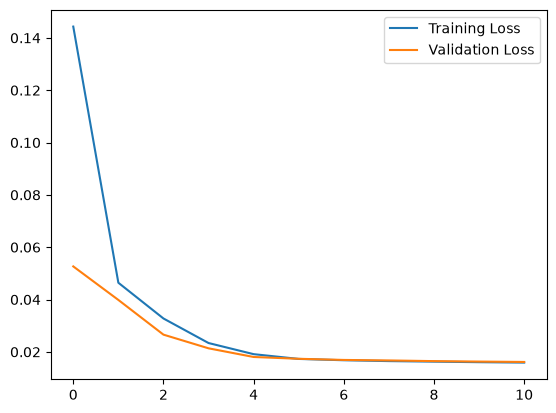

In [40]:
plt.plot(r.history['loss'])
plt.plot(r.history['val_loss'])
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()